# LeetCode #394: Decode String

https://leetcode.com/problems/decode-string/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Recursive Descent** | $O(\text{output length})$ | $O(\text{nesting depth})$ |
| **Optimal: Stack-Based ★** | $O(\text{output length})$ | $O(\text{nesting depth})$ |

---

## Understanding the Methods

### Recursive Descent
Parse the string recursively: when encountering a digit, read the full number, then recurse into the bracketed substring, and repeat the result the specified number of times.

### Optimal: Stack-Based ★
Use a stack to store (current_string, current_count) pairs. On `[`, push the current state and start fresh. On `]`, pop the previous state and append the current string repeated count times. On a digit, build the number. On a letter, append to the current string.

**Why this is better than Recursive Descent:** Both approaches have the same complexity, but the stack-based solution avoids recursion overhead and is easier to implement iteratively without managing a global index.

**Constraints:**
* 1 <= s.length <= 30
* s consists of lowercase English letters, digits, and square brackets
* s is guaranteed to be a valid input
* All integers in s are in the range [1, 300]

## Solutions

### C#

In [ ]:
public class Solution {
    public string DecodeString(string s) {
        var strStack = new Stack<string>();
        var numStack = new Stack<int>();
        string cur = "";
        int num = 0;
        foreach (char c in s) {
            if (char.IsDigit(c)) {
                num = num * 10 + (c - '0');
            } else if (c == '[') {
                strStack.Push(cur);
                numStack.Push(num);
                cur = "";
                num = 0;
            } else if (c == ']') {
                int repeat = numStack.Pop();
                string prev = strStack.Pop();
                cur = prev + string.Concat(Enumerable.Repeat(cur, repeat));
            } else {
                cur += c;
            }
        }
        return cur;
    }
}

### Python

In [ ]:
class Solution:
    def decodeString(self, s: str) -> str:
        stack = []
        cur = ""
        num = 0
        for c in s:
            if c.isdigit():
                num = num * 10 + int(c)
            elif c == '[':
                stack.append((cur, num))
                cur = ""
                num = 0
            elif c == ']':
                prev, repeat = stack.pop()
                cur = prev + cur * repeat
            else:
                cur += c
        return cur

### Go

In [ ]:
import "strings"

func decodeString(s string) string {
    type frame struct {
        str string
        num int
    }
    stack := []frame{}
    cur := ""
    num := 0
    for _, c := range s {
        if c >= '0' && c <= '9' {
            num = num*10 + int(c-'0')
        } else if c == '[' {
            stack = append(stack, frame{cur, num})
            cur = ""
            num = 0
        } else if c == ']' {
            f := stack[len(stack)-1]
            stack = stack[:len(stack)-1]
            cur = f.str + strings.Repeat(cur, f.num)
        } else {
            cur += string(c)
        }
    }
    return cur
}

### Rust

In [ ]:
impl Solution {
    pub fn decode_string(s: String) -> String {
        let mut stack: Vec<(String, usize)> = Vec::new();
        let mut cur = String::new();
        let mut num: usize = 0;
        for c in s.chars() {
            if c.is_ascii_digit() {
                num = num * 10 + (c as usize - '0' as usize);
            } else if c == '[' {
                stack.push((cur.clone(), num));
                cur.clear();
                num = 0;
            } else if c == ']' {
                let (prev, repeat) = stack.pop().unwrap();
                cur = prev + &cur.repeat(repeat);
            } else {
                cur.push(c);
            }
        }
        cur
    }
}

## Example Scenarios

### 1. Common Case — Two Independent Groups
**Input:** `s = "3[a]2[bc]"`
Scan left to right with two stacks. On `[`, push the current string and the repeat count `k`, then reset both. On `]`, pop them and splice `prev + current * k`. `3[a]` -> `"aaa"`, `2[bc]` -> `"bcbc"`, concatenated. **Output:** `"aaabcbc"`

### 2. Slightly Complex — Nested Brackets
**Input:** `s = "3[a2[c]]"`
Nesting is exactly what the stack handles: the inner group is decoded first and folded into the outer group's current string before the outer `]` repeats it. Inner `2[c] = "cc"` makes `"acc"`; outer `3[...]` repeats it. **Output:** `"accaccacc"`

### 3. Edge Case: Time Factor — Multi-Digit Repeat Explodes Output
**Input:** `s = "10[ab]"`
`k` can be two or more digits, built with `k = k*10 + digit`. The output length is the product of all enclosing counts, so it can grow far faster than the input. `k = 10`, `"ab"` repeated 10 times = 20 characters. **Output:** `"abababababababababab"`

### 4. Edge Case: Space Factor — Deep Nesting Drives Stack Depth
**Input:** `s = "2[2[2[b]]]"`
Each unmatched `[` adds one frame to both stacks; the maximum depth equals the nesting level, so space is $O(\text{depth} + \text{output})$. Three levels double `"b"` three times. **Output:** `"bbbbbbbb"`

### 5. Almost-Impossible but Plausible — Letters Outside Any Bracket
**Input:** `s = "abc3[cd]xyz"`
Plain letters with no surrounding `[` are appended straight to the output; the stacks stay empty between groups and only fill up around the bracketed segment. `"abc" + 3[cd]="cdcdcd" + "xyz"`. **Output:** `"abccdcdcdxyz"`


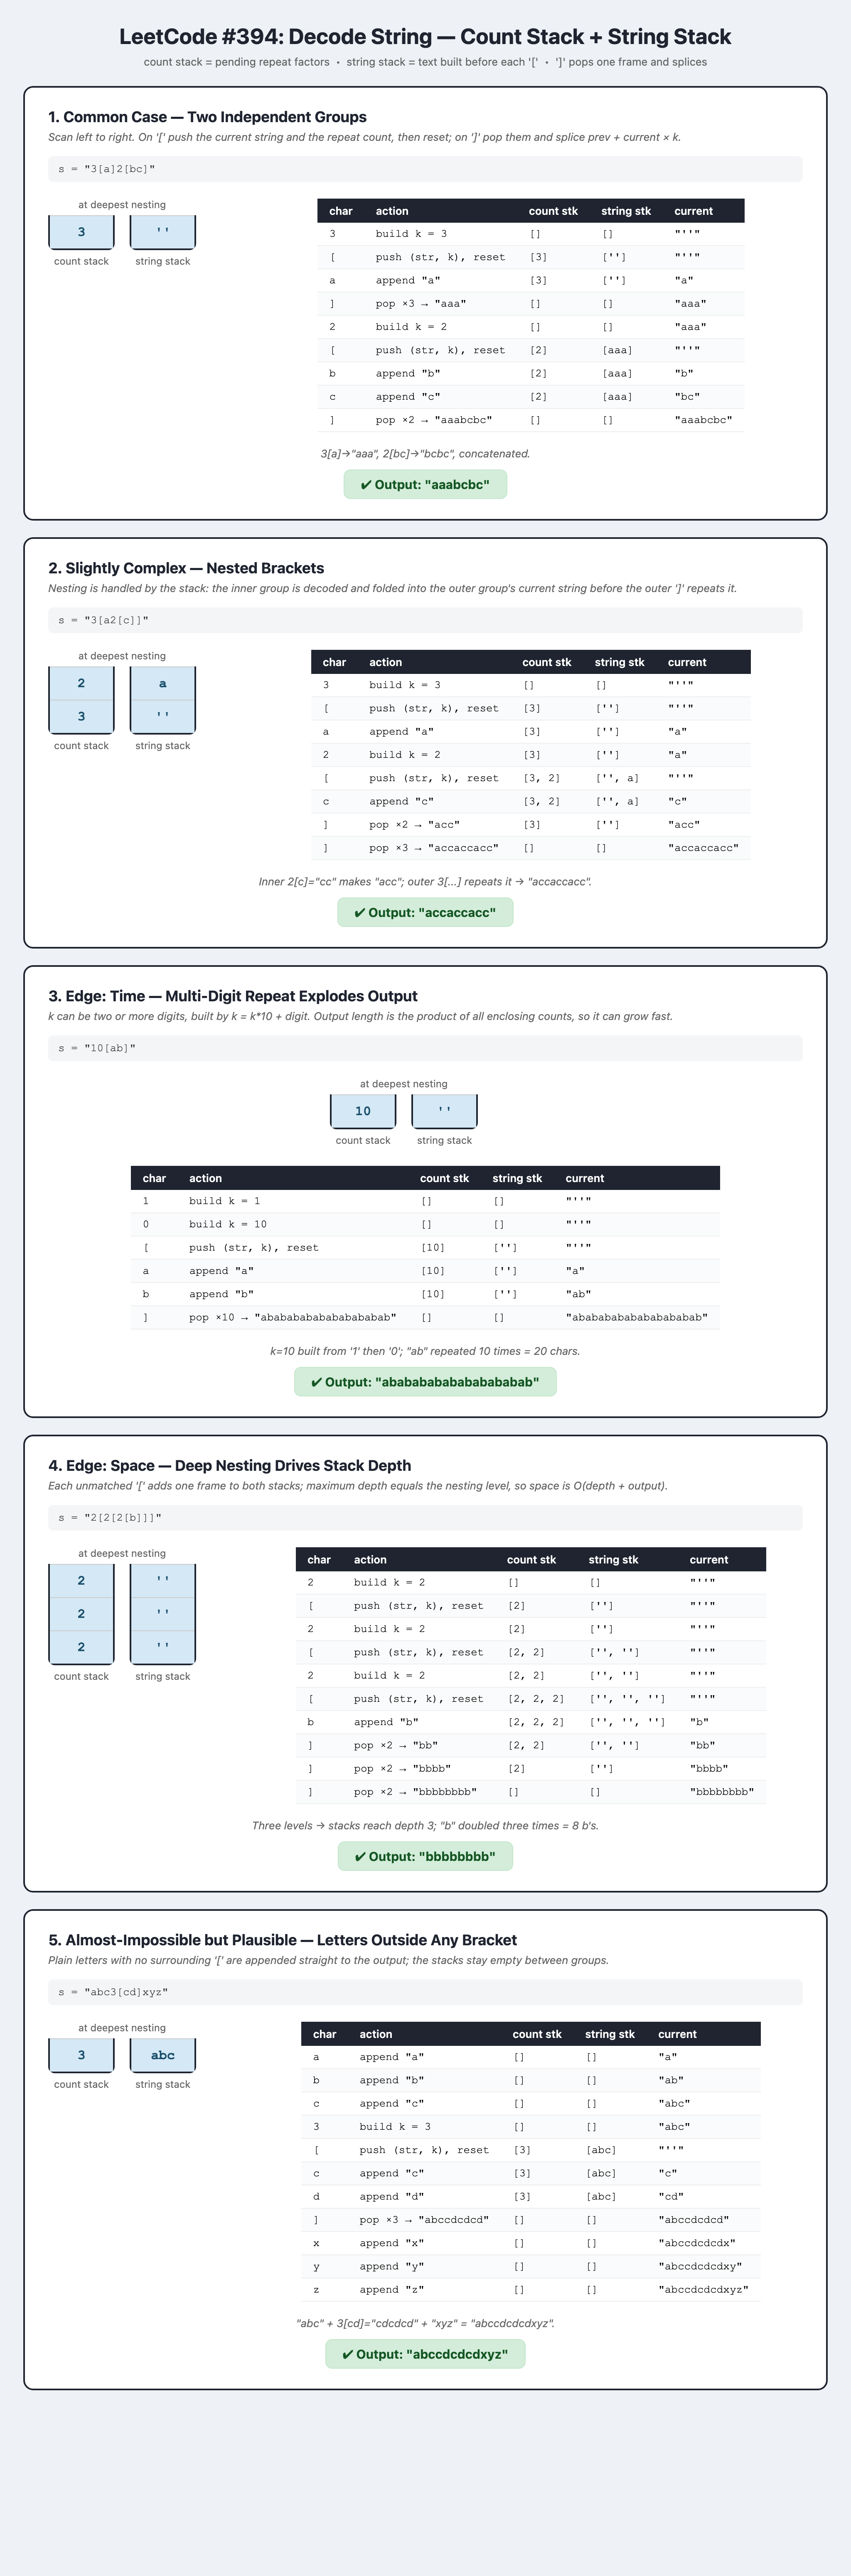